# Inspection of The Results

After all the experiments were ran, it is time to inspect and analyze the outcome. There will be the following parts to that:
1. General inspection of constraint properties, excluding coverage and regularity. The subjects of the inspection will be the distributions of the constraints by 1) the type of linguistic information they employ; 2) their target item.
2. General inspection of the coverage and regularity measures. At this step, the obtained values will be inspected, which includes the analysis of their distribution and correlation.
3. Inspection of item against type regularity values. This inspection gives an idea about the presence of negative outliers within covered items of the constraints.
4. Inspection of the extent to which the claims about the constraints made in the literature are supported by the data. That includes comparison of the quantifiers specified in the constraint definitions ("regularly", "mostly" etc.) and the obtained item regularity values. We concentrate on the item variant since we want a more balanced estimation not affected by productive outliers.
5. Inspection of the extent to which our suggestions to the definitions of not fully supported constraints are supported by the data.

In [1]:
# project-level pwd
%cd ..

/Users/maksimshmalts/Documents/DieKonstraintsPrivat/semrel_comp_corp_study-private


In [2]:
import os
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
# from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import statsmodels.formula.api as smf
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.markers import MarkerStyle
from collections import Counter, defaultdict
from itertools import product, pairwise, combinations
import yaml
from typing import List, Tuple

from data_utils import load_datasets
from check_applicability.regularity_scale import REGULARITY_SCALE

## 1. General Inspection of Constraint Properties

Our goal for this step of inspection is to retrieve the following:
1. The distribution of the constraints by the type of linguistic information they employ.
2. The distribution of the constraints by their target items.

Both properties are retrievable directly from the [master constraints file](../constraints/constraints_all_revised.yaml) so we load and access it here.

In [3]:
constr_path = "constraints/constraints_all_revised.yaml"

appl_stat_dir = "out/constraints/applicability_statistics"
constr_stat_dir = "out/constraints/constraint_statistics/"

# os.makedirs(appl_stat_dir, exist_ok=True)
os.makedirs(constr_stat_dir, exist_ok=True)

In [4]:
save_tsv = lambda df, path: df.to_csv(
    path,
    sep="\t",
    header=True,
    index=True
)

save_cstat_tsv = lambda df, name: save_tsv(
    df,
    os.path.join(constr_stat_dir, f"{name}.tsv")
)

save_astat_tsv = lambda df, name: save_tsv(
    df,
    os.path.join(appl_stat_dir, f"{name}.tsv")
)

In [5]:
# load constraints and dataset specs
with open(constr_path, encoding="utf-8") as f:
    yamls = list(yaml.safe_load_all(f))
    constraints: dict = yamls[-1]["constraints"]
    data_specs: dict = yamls[-2]["datasets"]

# load datasets
datasets = {
    dname: getattr(load_datasets, d["load_func"])(d["filepath"])
    for dname, d in data_specs.items()
}

### 1.1. Distribution of Constraints by Linguistic Information Type

Beside the linguistic info type, we will also distinguish between the application type (P2l/L2P).

In [6]:
ling_type_data = {
    "p2l": defaultdict(int),
    "l2p": defaultdict(int)
}

for c_id, constraint in constraints.items():
    if c_id == "def-0": # disregard the default constraint
        continue
    ling_type = sorted(constraint["ling_info_type"])    # sort for multiple types
    ling_type_str = "+".join(ling_type)
    appl_type = c_id.split(":")[0]
    ling_type_data[appl_type][ling_type_str] += 1

ling_types = pd.DataFrame(
    data=ling_type_data
).fillna(0).astype(int).sort_index()

save_cstat_tsv(ling_types, "ling_types")
ling_types

,p2l,l2p
derivational,9,2
derivational+morphological,1,1
derivational+morphological+phonological,1,0
derivational+phonological,0,3
derivational+semantic,2,0
lexical,1,4
lexical+morphological,0,1
lexical+morphological+phonological+semantic,0,1
lexical+semantic,1,0
morphological,6,6


In [7]:
ling_types["p2l"].sum().item(), ling_types["l2p"].sum().item()

(41, 22)

In [8]:
domains = ["morphological", "derivational", "phonological", "semantic", "lexical"]

domain_df = pd.Series(
	index=domains,
	data=
	{
		t: ling_types[
			ling_types.index.str.contains(t)
		].sum().sum().item()
		for t in domains
	}
)

save_cstat_tsv(domain_df, "involved_domains")
domain_df

morphological    33
derivational     19
phonological     18
semantic         19
lexical           8
dtype: int64

### 1.2. Distribution of Constraints by Target Item

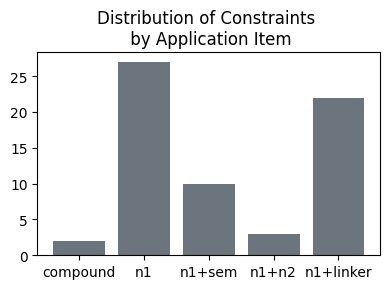

In [9]:
appl_items = [c["appl_item"] for c in constraints.values()]
counts = Counter(appl_items)
keys, values = counts.keys(), counts.values()

plt.figure(figsize=(4, 3))

bars = plt.bar(keys, values, color="#6c757d")

plt.title("Distribution of Constraints \n by Application Item")

plt.tight_layout()
plt.savefig(
    os.path.join(constr_stat_dir, "appl_item_distr.png"),
    dpi="figure"
)
plt.show()

Additionally, we want to know which number of possible items each type has. For that, we need to access GeCoDB_v06.

In [10]:
appl_item_counts_data = defaultdict(dict)

# TODO: optimize
for c_id, dname in product(constraints, data_specs):
    constr = constraints[c_id]
    if dname not in constr["datasets_n_appl_items"]:
        continue
    appl_item_counts_data[constr["appl_item"]][dname] = constr["datasets_n_appl_items"][dname]

appl_item_counts = pd.DataFrame(appl_item_counts_data).fillna(0).astype(int)

save_cstat_tsv(appl_item_counts, "appl_item_counts")
appl_item_counts

,compound,n1,n1+sem,n1+n2,n1+linker
gecodb_v06,282767,3614,0,0,4870
gecodb_v07,275411,3594,0,0,4743
gecodb_v07_gn,48980,3320,0,48664,3587
sp18_pl_constr,0,0,78,0,88


## 2. General Inspection of The Coverage and Regularity Measures

Here, we load the general applicability statistics table and retrieve three things:
1. Scatter plots of coverage against regularity in two variants each (item, type).
    * A shared plot.
    * P2L vs L2P.
2. Central tendency measures of the distributions (shared, P2L, L2P).
3. Qualitative analysis of the values clusters.

### 2.1. Draw Scatter Plot

In [11]:
stats = pd.read_csv(
    os.path.join(appl_stat_dir, "appl_statistics_summary.tsv"),
    sep="\t",
    index_col=(0, 1),
    header=0
).dropna()  # remove non-implemented constraints

stats

appl_item  n_appl_items  \
constr_id                 dataset                                   
def-0                     gecodb_v06       compound      282767.0   
                          gecodb_v07       compound      275411.0   
                          gecodb_v07_gn    compound       48980.0   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06             n1        3614.0   
                          gecodb_v07             n1        3594.0   
...                                             ...           ...   
l2p:es|mono_syl           gecodb_v07_gn   n1+linker        3587.0   
l2p:0_uml                 gecodb_v06      n1+linker        4870.0   
                          gecodb_v07      n1+linker        4743.0   
                          gecodb_v07_gn   n1+linker        3587.0   
l2p:pl_marker|def-pl      sp18_pl_constr  n1+linker          88.0   

                                                quantifier  cvg_item_abs  \
constr_id                 dataset                                          
def-0                     gecodb_v06              majority      282767.0   
                          gecodb_v07              majority      275411.0   
                          gecodb_v07_gn           majority       48980.0   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06      almost regularly         241.0   
                          gecodb_v07      almost regularly         240.0   
...                                                    ...           ...   
l2p:es|mono_syl           gecodb_v07_gn                all          36.0   
l2p:0_uml                 gecodb_v06                   all          17.0   
                          gecodb_v07                   all          15.0   
                          gecodb_v07_gn                all           5.0   
l2p:pl_marker|def-pl      sp18_pl_constr              tend          40.0   

                                          cvg_item  cvg_type  reg_item  \
constr_id                 dataset                                        
def-0                     gecodb_v06         1.000     1.000     0.578   
                          gecodb_v07         1.000     1.000     0.577   
                          gecodb_v07_gn      1.000     1.000     0.573   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06         0.067     0.066     0.954   
                          gecodb_v07         0.067     0.065     0.958   
...                                            ...       ...       ...   
l2p:es|mono_syl           gecodb_v07_gn      0.010     0.015     0.972   
l2p:0_uml                 gecodb_v06         0.003     0.000     1.000   
                          gecodb_v07         0.003     0.000     1.000   
                          gecodb_v07_gn      0.001     0.000     1.000   
l2p:pl_marker|def-pl      sp18_pl_constr     0.455     0.465     0.146   

                                          reg_type  n_violations  \
constr_id                 dataset                                  
def-0                     gecodb_v06         0.578    119391.000   
                          gecodb_v07         0.577    116594.000   
                          gecodb_v07_gn      0.573     20890.000   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06         0.936        11.047   
                          gecodb_v07         0.939        10.051   
...                                            ...           ...   
l2p:es|mono_syl           gecodb_v07_gn      0.941         1.000   
l2p:0_uml                 gecodb_v06         1.000         0.000   
                          gecodb_v07         1.000         0.000   
                          gecodb_v07_gn      1.000         0.000   
l2p:pl_marker|def-pl      sp18_pl_constr     0.153        34.159   

                                         is_productive is_regular  \
constr_id                 dataset                                   
def-0                     gecodb_v06             False      False   
                          gecodb_v07             False      False   
                          gecod

In [12]:
stat_ids = np.unique([ind[0] for ind in stats.index])
len(stat_ids)

53

In [13]:
np.char.startswith(stat_ids, "p2l:").sum().item(), np.char.startswith(stat_ids, "l2p:").sum().item()

(35, 17)

In [14]:
stats = stats.swaplevel(0, 1)

Now draw the plots. We start with the shared plot.

In [15]:
dot_kw = {
    "facecolors": "none",   # hollow inside
    "edgecolors": "black",  # outline
    "s": 100                 # marker size
}

line_kw = {
    "color": "black",
    "linewidth": 0.5,
    "linestyle": "--",
    "alpha": 0.6
}

line_label_kw = {
    "fontsize": 7,
    "alpha": 0.8,
    "clip_on": False
}

# https://matplotlib.org/stable/api/markers_api.html#module-matplotlib.markers
markers = {
    # add with new datasets
    "gecodb_v06": "o",
    "gecodb_v07": "v",
    "gecodb_v07_gn": "*",
    "sp18_pl_constr": "p",
    # "s"
}

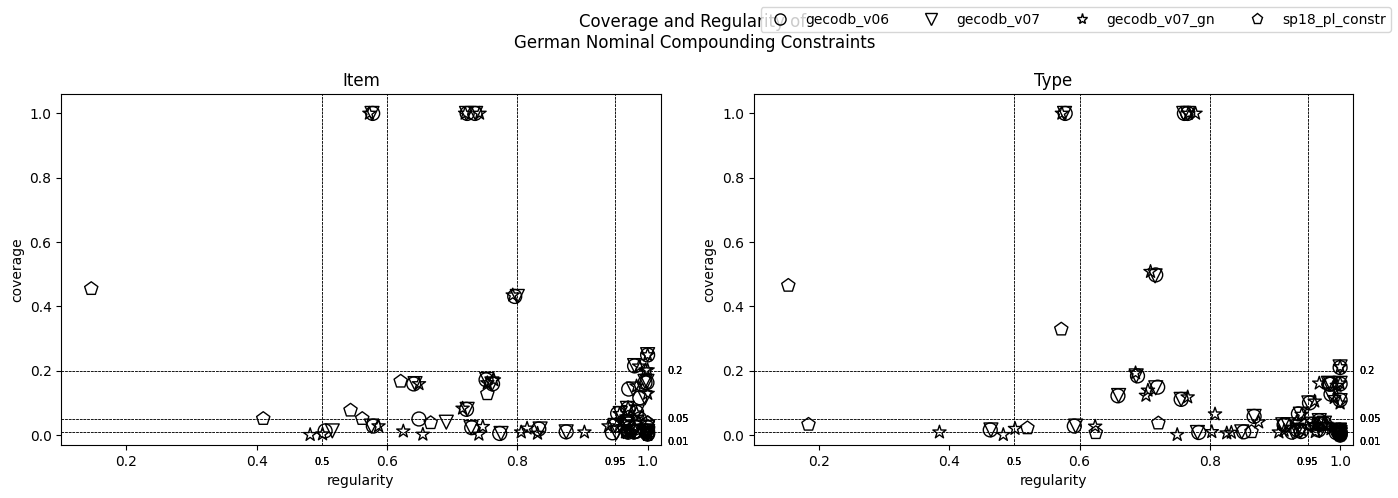

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

legend = []
for dname in data_specs:

    stats_dname = stats.loc[dname]
    marker = markers[dname]

    # item cvg/reg values
    axes[0].scatter(
        stats_dname["reg_item"],
        stats_dname["cvg_item"],
        **dot_kw,
        marker=marker
    )
    axes[0].set_xlabel("regularity")
    axes[0].set_ylabel("coverage")
    axes[0].set_title("Item")


    # type cvg/reg values
    axes[1].scatter(
        stats_dname["reg_type"],
        stats_dname["cvg_type"],
        **dot_kw,
        marker=marker
    )
    axes[1].set_xlabel("regularity")
    axes[1].set_ylabel("coverage")
    axes[1].set_title("Type")

    for ax in axes:

        ax.set_xlim(0.1, 1.02)
        ax.set_ylim(-0.03, 1.06)

        # horizontal lines for coverage
        for y in [0.01, 0.05, 0.2]:
            ax.axhline(y=y, **line_kw)
            ax.text(
                1.03, y - (0.03 * (y == 0.01)), y,
                va="center", ha="left", **line_label_kw
            )

        # vertical lines for regularity
        for x in [0.5, 0.6, 0.8, 0.95]:
            ax.axvline(x=x, **line_kw)
            if not x in ax.get_xticks().round(2):
                ax.text(
                    x, -0.1, x,
                    va="bottom", ha="center",
                    **line_label_kw
                )

    legend_handle = mlines.Line2D(
        [], [], color="black", marker=marker, linestyle="None",
        markersize=8, markerfacecolor="none", label=dname
    )
    legend.append(legend_handle)

fig.suptitle(
    "Coverage and Regularity of \n"
    "German Nominal Compounding Constraints"
)
fig.legend(handles=legend, loc="upper right", ncol=len(legend))

plt.tight_layout()
plt.savefig(
    os.path.join(appl_stat_dir, "cvg_reg.png"),
    dpi="figure"
)
plt.show()

In [17]:
r = lambda x, y: x.corr(y, method="pearson")

mw_gecodb_versions_data = {}
for g0, g1 in combinations([k for k in data_specs if k.startswith("gecodb")], 2):
    corr_res = {}
    for param in [("reg", "item"), ("reg", "type"), ("cvg", "item"), ("cvg", "type")]:
        param_str = "_".join(param)
        mw = mannwhitneyu(stats.loc["gecodb_v06", param_str], stats.loc["gecodb_v07", param_str])
        corr_res[param] = {
            "U": mw.statistic,
            "p": mw.pvalue,
            "r": r(stats.loc["gecodb_v06", param_str], (stats.loc["gecodb_v07", param_str]))
        }
    mw_gecodb_versions_data[f"{g0} vs. {g1}"] = pd.DataFrame(corr_res).round(3)

mw_gecodb_versions = pd.concat(mw_gecodb_versions_data, names=["comparison"])

save_astat_tsv(mw_gecodb_versions, "mw_gecodb_versions")
mw_gecodb_versions

reg             cvg         
                                   item     type   item     type
comparison                                                      
gecodb_v06 vs. gecodb_v07    U  770.500  761.500  760.5  755.500
                             p    0.924    0.996    1.0    0.964
                             r    0.999    1.000    1.0    1.000
gecodb_v06 vs. gecodb_v07_gn U  770.500  761.500  760.5  755.500
                             p    0.924    0.996    1.0    0.964
                             r    0.999    1.000    1.0    1.000
gecodb_v07 vs. gecodb_v07_gn U  770.500  761.500  760.5  755.500
                             p    0.924    0.996    1.0    0.964
                             r    0.999    1.000    1.0    1.000

=> we can use either

In [18]:
set(stats.loc["gecodb_v07_gn"].index) & set(stats.loc["sp18_pl_constr"].index)

set()

In [19]:
stats_flat = stats.loc[["gecodb_v07_gn", "sp18_pl_constr"]]    \
    .reset_index(level=0, drop=False)

stats_flat = stats_flat[stats_flat["reg_item"] >= 0.5]

stats_flat_p2l = stats_flat[stats_flat.index.str.startswith("p2l:")]
stats_flat_l2p = stats_flat[stats_flat.index.str.startswith("l2p:")]

stats_flat

,dataset,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,,
def-0,gecodb_v07_gn,compound,48980.0,majority,48980.0,1.000,1.000,0.573,0.573,20890.000,False,False,low regularity,low regularity,supported
p2l:decl_cl:pl:#0-0|def-0,gecodb_v07_gn,n1,3320.0,almost regularly,218.0,0.066,0.064,0.957,0.941,9.303,True,False,high regularity,high regularity,supported
p2l:decl_cl:pl:#s-0,gecodb_v07_gn,n1,3320.0,almost all,117.0,0.035,0.029,0.965,0.962,4.080,True,True,high regularity,regular,supported+
p2l:decl_cl:pl:#e-0|def-0,gecodb_v07_gn,n1,3320.0,mostly,537.0,0.162,0.193,0.754,0.686,131.933,False,False,low regularity,moderate regularity,supported+
p2l:decl_cl:pl:#er-0/er|def-0/er,gecodb_v07_gn,n1,3320.0,mostly,69.0,0.021,0.065,0.815,0.808,12.790,True,False,low regularity,moderate regularity,supported+
p2l:decl_cl:pl:#er-0/er|mass-interpr-0,gecodb_v07_gn,n1,3320.0,tend,6.0,0.002,0.009,0.741,0.906,1.554,True,True,moderate regularity,regular,supported+
p2l:decl_cl:pl:#er-0/er|anim-er,gecodb_v07_gn,n1,3320.0,may,10.0,0.003,0.010,0.501,0.803,4.989,False,False,low regularity,low regularity,supported
p2l:decl_cl:pl:#e_uml-0|def-0,gecodb_v07_gn,n1,3320.0,mostly,274.0,0.083,0.118,0.716,0.766,77.935,False,False,low regularity,moderate regularity,supported+
p2l:decl_cl:pl:#0_uml-0|def-0,gecodb_v07_gn,n1,3320.0,almost always,24.0,0.007,0.019,0.974,0.986,0.612,True,True,high regularity,regular,supported+


In [20]:
item_type_desc_data = {}
for param in [("reg", "item"), ("reg", "type"), ("cvg", "item"), ("cvg", "type")]:
    param_str = "_".join(param)
    item_type_desc_data[param] = stats_flat[param_str] \
        .describe(percentiles=[0.5, 0.9])

item_type_desc = pd.concat(item_type_desc_data, axis=1).T.round(3)
save_astat_tsv(item_type_desc, "item_type_desc")
item_type_desc

count   mean    std    min    50%    90%  max
reg item   49.0  0.850  0.161  0.501  0.957  1.000  1.0
    type   49.0  0.865  0.151  0.501  0.941  1.000  1.0
cvg item   49.0  0.127  0.241  0.001  0.038  0.221  1.0
    type   49.0  0.123  0.245  0.000  0.029  0.235  1.0

In [21]:
mw_item_type = pd.DataFrame({
   param: {
        "U": (mw := mannwhitneyu(stats_flat[f"{param}_item"], stats_flat[f"{param}_type"])).statistic,
        "p": mw.pvalue,
        "r": r(stats_flat[f"{param}_item"], stats_flat[f"{param}_type"]),
        "mae": mean_absolute_error(stats_flat[f"{param}_item"], stats_flat[f"{param}_type"])
    }
    for param in ["cvg", "reg"]
}).round(3)

save_astat_tsv(mw_item_type, "mw_item_type")
mw_item_type

,cvg,reg
U,1250.000,1161.500
p,0.728,0.783
r,0.988,0.856
mae,0.023,0.049


=> we can use either

In [22]:
get_val_clusters = lambda stats, val, cp: pd.Series({
	f"{val}: [{left}-{right})": (
		(stats[f"{val}_item"] >= left) &
		(stats[f"{val}_item"] < right)
	).sum()
	for left, right in pairwise(cp)
})

critical_points_cvg = [0.0, 0.05, 0.2, 1.01]
cvg_clusters = pd.DataFrame(
    {
        "all": get_val_clusters(stats_flat, "cvg", critical_points_cvg),
        "P2L": get_val_clusters(stats_flat_p2l, "cvg", critical_points_cvg),
        "L2P": get_val_clusters(stats_flat_l2p, "cvg", critical_points_cvg)
    }
)

critical_points_reg = [0.5, 0.6, 0.8, 0.95, 1.01]
reg_clusters = pd.DataFrame(
    {
        "all": get_val_clusters(stats_flat, "reg", critical_points_reg),
        "P2L": get_val_clusters(stats_flat_p2l, "reg", critical_points_reg),
        "L2P": get_val_clusters(stats_flat_l2p, "reg", critical_points_reg)
    }
)

partition = pd.DataFrame({"all": "", "P2L": "", "L2P": ""}, index=[""] * 2)

cvg_reg_clusters = pd.concat((cvg_clusters, partition, reg_clusters))
save_astat_tsv(cvg_reg_clusters, "cvg_reg_clusters")
cvg_reg_clusters

,all,P2L,L2P
cvg: [0.0-0.05),28,16,12
cvg: [0.05-0.2),13,11,2
cvg: [0.2-1.01),8,5,2
,,,
,,,
reg: [0.5-0.6),5,4,0
reg: [0.6-0.8),14,12,2
reg: [0.8-0.95),5,3,2
reg: [0.95-1.01),25,13,12


In [23]:
mw_p2l_l2p_data = {}
for sign, a in [("<>", "two-sided"), (">", "greater"), ("<", "less")]:
    res = pd.DataFrame({
        param: {
            f"U": (mw := mannwhitneyu(
                stats_flat_p2l[f"{param}_item"],
                stats_flat_l2p[f"{param}_item"],
                alternative=a
            )).statistic,
            f"p": mw.pvalue
        }
        for param in ["cvg", "reg"]
    })
    mw_p2l_l2p_data[f"P2L{sign}L2P"] = res
mw_p2l_l2p = pd.concat(mw_p2l_l2p_data, names=["alternative"]).round(3)

save_astat_tsv(mw_p2l_l2p, "mw_p2l_l2p")
mw_p2l_l2p

cvg      reg
alternative                    
P2L<>L2P    U  353.000  123.500
            p    0.034    0.004
P2L>L2P     U  353.000  123.500
            p    0.017    0.998
P2L<L2P     U  353.000  123.500
            p    0.984    0.002

In [24]:
corr_cvg_reg = pd.DataFrame({
    "r": {
        v: stats_flat[f"reg_{v}"].corr(stats_flat[f"cvg_{v}"], method="pearson")
        for v in ["item", "type"]
    }
}).T.round(3)

save_astat_tsv(corr_cvg_reg, "corr_cvg_reg")
corr_cvg_reg

,item,type
r,-0.267,-0.344


In [25]:
ling_type_mtrx = stats_flat.apply(
    lambda row: {
        ling_type: True
        for ling_type in constraints[row.name]["ling_info_type"]
    },
    axis=1,
    result_type="expand"
)
ling_type_mtrx.fillna(False, inplace=True)
ling_type_mtrx.drop(columns=["default"], inplace=True)

In [26]:
cols = ["morphological", "derivational", "phonological", "semantic", "lexical"]
stats_flat = pd.concat((stats_flat, ling_type_mtrx), axis=1)
stats_flat.drop(
    # the default
    stats_flat[stats_flat.apply(
        lambda row: row[cols].sum() == 0,
        axis=1
    )].index,
    inplace=True
)
stats_flat.sample(5)

,dataset,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level,morphological,derivational,semantic,phonological,lexical
constr_id,,,,,,,,,,,,,,,,,,,,
p2l:decl_cl:pl:#er-0/er|anim-er,gecodb_v07_gn,n1,3320.0,may,10.0,0.003,0.010,0.501,0.803,4.989,False,False,low regularity,low regularity,supported,True,False,True,False,False
l2p:s|f_poly_syl,gecodb_v07_gn,n1+linker,3587.0,all,723.0,0.202,0.161,1.000,1.000,0.000,True,True,regular,regular,supported,True,False,False,True,False
l2p:e_uml,gecodb_v07_gn,n1+linker,3587.0,all,12.0,0.003,0.002,1.000,1.000,0.000,True,True,regular,regular,supported,True,False,False,False,False
l2p:er|smpx,gecodb_v07_gn,n1+linker,3587.0,most,31.0,0.009,0.014,0.903,0.914,3.000,True,True,low regularity,regular,supported+,False,True,False,False,False
l2p:s|smpx_mn,gecodb_v07_gn,n1+linker,3587.0,almost all,95.0,0.026,0.040,0.979,0.875,2.000,True,True,high regularity,regular,supported+,True,False,False,False,False


In [27]:
# https://matplotlib.org/stable/gallery/color/named_colors.html
colors = {
    "morphological": "red",
    "derivational": "green",
    "phonological": "blue",
    "semantic": "gold",
    "lexical": "blueviolet"
}
matplotlib.rcParams["hatch.linewidth"] = 2.0

def get_dots(ling_types: List[str], marker: str) -> dict:
    ling_types = sorted(ling_types)
    match len(ling_types):
        case 1:
            dots = [{
                "facecolors": colors[ling_types[0]],
                
                "marker": marker
            }]
        case 2:
            # two halves
            dots = [
                {
                    "facecolors": colors[ling_types[0]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="left"
                    )
                },
                {
                    "facecolors": colors[ling_types[1]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="right"
                    )
                }
            ]
        case 3:
            # two halves + hatch
            dots = [
                {
                    "facecolors": colors[ling_types[0]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="left"
                    )
                },
                {
                    "facecolors": colors[ling_types[1]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="right"
                    )
                },
                {
                    "facecolors": "none",
                    "edgecolors": colors[ling_types[2]],
                    "hatch": "////",
                    "marker": marker
                }
            ]
        case _:
            raise NotImplemented
    return dots    

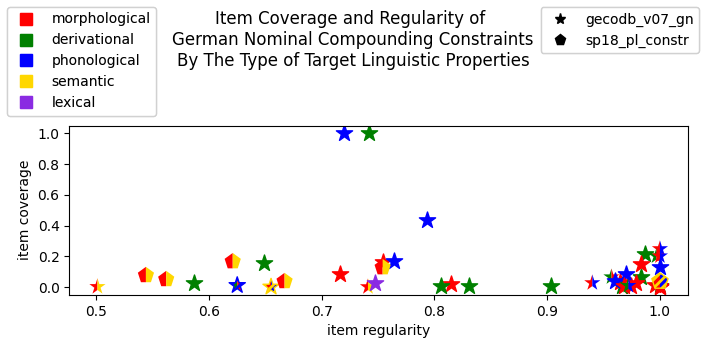

In [28]:
fig, axis = plt.subplots(1, 1, figsize=(7, 3.5))

for c_id, row in stats_flat.iterrows():

    if c_id == "def-0":
        continue

    marker = markers[row["dataset"]]
    dots = get_dots(constraints[c_id]["ling_info_type"], marker)
    for dot in dots:
        axis.scatter(
            row["reg_item"],
            row["cvg_item"],
            s=150,
            **dot
        )

axis.set_xlabel("item regularity")
axis.set_ylabel("item coverage")

legend_dataset = [
    mlines.Line2D(
        [], [], color="black", marker=markers[dname], linestyle="None",
        markersize=8, markerfacecolor="black", label=dname
    )
    for dname in stats_flat["dataset"].unique()
]
legend_colors = [
    mlines.Line2D(
        [], [], color=color, marker="s", linestyle="None",
        markersize=8, markerfacecolor=color, label=ling_type
    )
    for ling_type, color in colors.items()
    if ling_type in stats_flat
]

fig.suptitle(
    "Item Coverage and Regularity of \n"
    "German Nominal Compounding Constraints\n"
    "By The Type of Target Linguistic Properties"
)
legc = fig.legend(handles=legend_colors, loc="upper left")
legd = fig.legend(handles=legend_dataset, loc="upper right")
axis.add_artist(legc)
axis.add_artist(legd)

plt.tight_layout()
plt.subplots_adjust(top=0.65)
plt.savefig(
    os.path.join(appl_stat_dir, "cvg_reg_vs_ling_type.png"),
    dpi="figure"
)
plt.show()

In [29]:
# X = stats_flat[["morphological", "derivational", "phonological", "semantic"]]
# y = {
#     "cvg": stats_flat["cvg_item"],
#     "reg": stats_flat["reg_item"]
# }

# lr_cvg_reg_vs_ling_type_data = {}
# for param in ["cvg", "reg"]:
#     lr = LinearRegression(positive=False)
#     lr.fit(X, y[param])
#     lr_cvg_reg_vs_ling_type_data[param] = {
#         "intercept": lr.intercept_,
#         **{
#             f"coef_{ling_type}": lr.coef_[i]
#             for i, ling_type in enumerate(X.columns)
#         }
#     }

# lr_cvg_reg_vs_ling_type = pd.DataFrame(lr_cvg_reg_vs_ling_type_data)
# save_astat_tsv(lr_cvg_reg_vs_ling_type, "lr_cvg_reg_vs_ling_type")
# lr_cvg_reg_vs_ling_type

In [30]:
# the same as above but more informative:
ols = smf.ols(f"cvg_item ~ {' + '.join(cols)} + 1", data=stats_flat).fit()
with open(os.path.join(appl_stat_dir, "lr_cvg_vs_ling_type.txt"), "w") as out:
    out.write(str(ols.summary()))
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:               cvg_item   R-squared:                       0.117
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     1.109
Date:                Thu, 30 Jul 2026   Prob (F-statistic):              0.370
Time:                        13:41:17   Log-Likelihood:                 10.977
No. Observations:                  48   AIC:                            -9.954
Df Residuals:                      42   BIC:                             1.273
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.24

In [31]:
ols = smf.ols(f"reg_item ~ {' + '.join(cols)} + 1", data=stats_flat).fit()
with open(os.path.join(appl_stat_dir, "lr_reg_vs_ling_type.txt"), "w") as out:
    out.write(str(ols.summary()))
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:               reg_item   R-squared:                       0.305
Model:                            OLS   Adj. R-squared:                  0.222
Method:                 Least Squares   F-statistic:                     3.684
Date:                Thu, 30 Jul 2026   Prob (F-statistic):            0.00746
Time:                        13:41:17   Log-Likelihood:                 29.897
No. Observations:                  48   AIC:                            -47.79
Df Residuals:                      42   BIC:                            -36.57
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.85

Note that all non-confirmed constraints are semantic as well => the real picture is more severe

## 4. Inspection of The Extent to Which the Claims About the Constraints Made in The Literature Are Supported by The Data

The following steps are to be done for final inspection:
1. Manually inspect the support level of the claims in the empirical data. For each (analyzed) constraint, record the level of support. Since the definitions are mostly vague, base the decision on commonsense judgments. For the support level, we concentrate on the type variant of the measures since we focus on the linguistic side of the question (not real usage). There are 4 levels of support:
    * Supported. Full or very close correspondence between the quantifier and the empirical data. Examples: "regular" vs 0.99, "mostly" vs 0.75.
    * Partially supported. The gap is not critical yet noticeable. Examples: "regular" vs 0.93, "tends" vs 0.6, "sometimes" vs 0.9.
    * Not supported. The discrepancy between the quantifier and the empirical data is too significant to ignore. Examples: "regular" vs 0.85, "tends" vs 0.4.
    * NA: no data available (unreliable or semantic/lexical constraints).

Note: this steps is being conducted in the file with constraints definitions, see `constraints/constraints.yaml`. While it is being now made at the time of this inspection, we cannot reflect this processes here. After this step is done, we pull the results from this file and further inspect them in detail, specifically:

2. Inspect the distribution of the support levels.
3. Manually inspect the constraints that are only partially supported by the data or not supported at all.

### 4.1. Inspection of The Support Level

Done separately in `constraints/constraints.yaml`.

NEW SCALE:

0.5, 0.6, 0.8, 0.95 | regular

In [32]:
# # Yang 2016: 67
# 23 is an error in the original table,
# see Yang 2016: 62
# 100 / ln(100) ~= 21.715
yang_values = [10, 20, 50, 100, 200, 500, 1000, 5000]
irreg_tp_values_data = {
    "TP": {
        n: REGULARITY_SCALE._yang_theta(n)
        for n in yang_values
    },
    "ITP": {
        n: 1 - REGULARITY_SCALE._irreg_tolerance(n)
        for n in yang_values
    }
}
irreg_tp_values = pd.DataFrame(irreg_tp_values_data)
irreg_tp_values["TP"] = irreg_tp_values["TP"].astype(int)
irreg_tp_values["ITP"] = irreg_tp_values["ITP"].round(3)
save_astat_tsv(irreg_tp_values, "irreg_tp_values")
irreg_tp_values

,TP,ITP
10,4,0.770
20,6,0.850
50,12,0.922
100,21,0.954
200,37,0.974
500,80,0.988
1000,144,0.993
5000,587,0.998


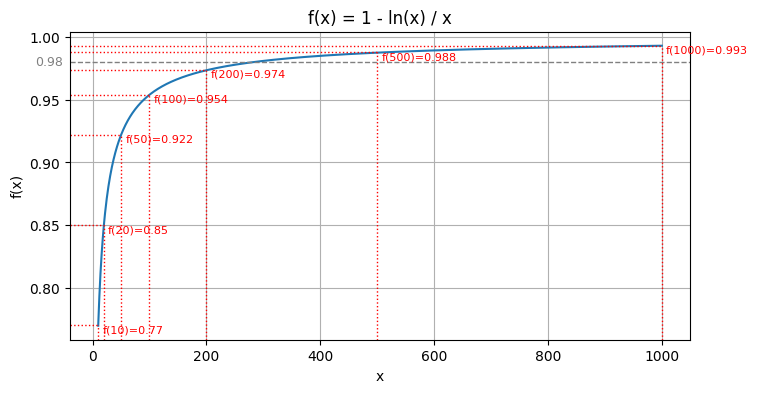

In [33]:
x = np.arange(10, 1001)
y = 1 - np.log(x) / x

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot(x, y)

# draw the old threshold
for x in [0.98]:
    ax.axhline(y=x, color="grey", linestyle="--", linewidth=1)
    ax.text(
        -100, x, x,
        va="center", ha="left", color="grey", fontsize=9
    )

# draw new threshold examples
for x, y in irreg_tp_values["ITP"].items():
    if x > 1000:
        continue
    x_max, y_max = ax.transAxes.inverted().transform(ax.transData.transform((x, y)))
    ax.axvline(x=x, ymax=y_max, color="red", linewidth=1, linestyle=":")
    ax.axhline(y=y, xmax=x_max, color="red", linewidth=1, linestyle=":")
    ax.text(x + 7.5, y - 0.0075, f"f({x})={y}", color="red", fontsize=8, va="bottom", ha="left")

plt.xlabel("x")
plt.ylabel("f(x)")

plt.title("f(x) = 1 - ln(x) / x")
plt.grid(True)
plt.savefig(
    os.path.join(appl_stat_dir, "irreg_threshold.png"),
    dpi="figure"
)
plt.show()

### 4.2. Inspection of Support Level Distribution

Now, we read the constraint definition file for inspection.

In [34]:
support_levels = pd.DataFrame({
    dname: {
        sl: (stats.loc[dname]["support_level"] == sl).sum()
        for sl in stats["support_level"].unique()
    }
    for dname in data_specs
})

save_astat_tsv(support_levels, "support_levels")
support_levels

,gecodb_v06,gecodb_v07,gecodb_v07_gn,sp18_pl_constr
supported,25,26,27,3
supported+,12,12,13,4
not supported,0,0,3,2
partially supported,2,1,1,0


In [35]:
constrs_by_itp = stats_flat.groupby(["is_productive", "is_regular"]).size() \
    .to_frame() \
    .rename(columns={0: "N"})

save_astat_tsv(constrs_by_itp, "constrs_by_itp")
constrs_by_itp

N
is_productive is_regular    
False         False       11
True          False       14
              True        23

In [36]:
unprod_constr = stats_flat[~stats_flat["is_productive"].astype(bool)]	\
	[["cvg_item_abs", "n_violations", "reg_item", "actual_reg_level"]]

unprod_constr.insert(
	1, "n_violations_allowed",
	unprod_constr["cvg_item_abs"].map(
		REGULARITY_SCALE._yang_theta
	).round(3)
)

save_astat_tsv(unprod_constr, "unprod_constr")
unprod_constr

,cvg_item_abs,n_violations_allowed,n_violations,reg_item,actual_reg_level
constr_id,,,,,
p2l:decl_cl:pl:#e-0|def-0,537.0,85.428,131.933,0.754,moderate regularity
p2l:decl_cl:pl:#er-0/er|anim-er,10.0,4.343,4.989,0.501,low regularity
p2l:decl_cl:pl:#e_uml-0|def-0,274.0,48.814,77.935,0.716,moderate regularity
p2l:drv:deverb_schwa$-0|def-0,94.0,20.690,38.801,0.587,low regularity
p2l:drv:prx_deverb-s,527.0,84.089,184.806,0.649,moderate regularity
p2l:phon_fin:F_stem_#t$-s,41.0,11.041,15.386,0.625,moderate regularity
p2l:phon_fin:schwa$-en|def-en,569.0,89.693,134.177,0.764,moderate regularity
p2l:tend:cmpx_morph-s|def-s,3320.0,409.486,855.716,0.742,moderate regularity
p2l:tend:cmpx_phon-s|def-s,3320.0,409.486,931.185,0.720,moderate regularity


### 4.3. Qualitative Inspection of Partially / Not Supported Constraints

Partially supported constraints.

In [55]:
def load_appl_index(dname):
    return pd.read_csv(
        os.path.join(appl_stat_dir, dname, "appl_index.tsv"),
        sep="\t",
        header=0,
        index_col="comp_gecodb",
        dtype=defaultdict(
            # to be able to parse NAs in boolean columns
            lambda: "boolean[pyarrow]",
            comp_gecodb=str,
            **{
                f"{c_id}_item": str
                for c_id in constraints
            }
        )
    )

def inspect_constr_appl(
    appl_index: pd.DataFrame, c_id: str,  only_violations: bool=True
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    # subsample the dataset stats
    sample = appl_index[
        # only covered compounds
        appl_index[c_id + "_is_applicable"]][[
        # only constraint_related columns 
        c_id + "_item", c_id + "_applies"
    ]]
    items = sample[c_id + "_item"].unique()
    example_dfs = []
    for item in items:
        # all compounds built with the item
        item_sample = sample[sample[c_id + "_item"] == item]
        Nbwi_total = len(item_sample)
        # exceptions built with the item
        item_sample_exc = item_sample[~(item_sample[c_id + "_applies"])]    \
            .drop(columns=[c_id + "_applies"])
        Nbwi_exc = len(item_sample_exc)
        perc_exc = round(Nbwi_exc / Nbwi_total, 3)
        if not only_violations:
            examples = item_sample.sample(1)
        else:
            if not len(item_sample_exc):
                continue
            examples = item_sample_exc.sample(1)
        examples[["Nbwi_total", "Nbwi_exc", "%_exc"]] = Nbwi_total, Nbwi_exc, perc_exc
        example_dfs.append(examples)
    example_df = pd.concat(example_dfs, axis=0)
    sort_by = "Nbwi_total" if not only_violations else "Nbwi_exc"
    example_df.sort_values(by=sort_by, inplace=True, ascending=False)
    return sample, example_df

In [56]:
to_inspect = []
for dname, dataset in datasets.items():

	out_dir = os.path.join(appl_stat_dir, dname, "unsupported_constr")
	os.makedirs(out_dir, exist_ok=True)

	appl_index = load_appl_index(dname)

	is_unsup = stats.loc[dname, "support_level"].isin(["partially supported", "not supported"])
	unsupported_constr = stats.loc[dname].loc[is_unsup]
	save_tsv(unsupported_constr, os.path.join(out_dir, "constr_list.tsv"))

	violations = []
	for c_id in unsupported_constr.index:
		sample, examples = inspect_constr_appl(appl_index, c_id)
		sample = dataset.loc[sample.index]
		c_id_alias = constraints[c_id]["func_alias"]	# avoid "/"s in ids
		save_tsv(sample, os.path.join(out_dir, f"{c_id_alias}_sample.tsv"))
		save_tsv(examples, os.path.join(out_dir, f"{c_id_alias}_summary.tsv"))
		violations.append(examples)

	to_inspect.append((unsupported_constr, violations))

GeCoDB_v06

In [57]:
unsupported_constr, violations = to_inspect[0]
unsupported_constr

,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,
p2l:drv:sfx:sfx-s|def-s,n1,3614.0,regularly,777.0,0.215,0.158,0.980,0.985,15.267,True,False,regular,high regularity,partially supported
l2p:n,n1+linker,4870.0,all,564.0,0.116,0.109,0.988,1.000,7.000,True,False,regular,high regularity,partially supported


In [58]:
# 121 N1s, 21 N1s that build ten or more exceptions;
# cumulative number of violations 15.267 with
# the number of covered items 777, which would
# require item regularity of 0.991
violations[0]

,p2l:drv:sfx:sfx-s|def-s_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
generation_+en_garten,generation,123,89,0.724
minderheit_+en_volk,minderheit,86,50,0.581
wirtschaft_vertreter,wirtschaft,683,49,0.072
spezialität_+en_händler,spezialität,33,33,1.000
süßigkeit_+en_verbot,süßigkeit,26,26,1.000
...,...,...,...,...
genehmigung_verfahren,genehmigung,78,1,0.013
kompression_strumpf,kompression,20,1,0.050
kleidung_stück,kleidung,58,1,0.017


In [59]:
# several mysanalyses (removed in GeCoDB_v07) => ignore
violations[1]

,l2p:n_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
mittel_+n_dorf,mittel+en,2,2,1.0
nachbar_+n_land,nachbar+en,1,1,1.0
zwiebel_+n_schneide,zwiebel+en,1,1,1.0
windel_+n_wechsel,windel+en,1,1,1.0
vokabel_+n_pauke,vokabel+en,1,1,1.0
waffel_+n_backe,waffel+en,1,1,1.0
semmel_+n_knödel,semmel+en,1,1,1.0


GeCoDB_v07

In [60]:
unsupported_constr, violations = to_inspect[1]
unsupported_constr

,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,
p2l:drv:sfx:sfx-s|def-s,n1,3594.0,regularly,777.0,0.216,0.16,0.98,0.985,15.209,True,False,regular,high regularity,partially supported


In [61]:
# 121 N1s, 21 N1s that build ten or more exceptions;
# cumulative number of violations 15.209 with
# the number of covered items 777, which would
# require item regularity of 0.991
violations[0]

,p2l:drv:sfx:sfx-s|def-s_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
generation_+en_kluft,generation,120,86,0.717
minderheit_+en_veranstaltung,minderheit,84,49,0.583
wirtschaft_förderung,wirtschaft,674,48,0.071
spezialität_+en_angebot,spezialität,33,33,1.000
süßigkeit_+en_händler,süßigkeit,26,26,1.000
...,...,...,...,...
festung_sturm,festung,61,1,0.016
genehmigung_verfahren,genehmigung,77,1,0.013
kompression_strumpf,kompression,20,1,0.050


GeCoDB_v07_GN

In [62]:
unsupported_constr, violations = to_inspect[2]
unsupported_constr

,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,
p2l:decl_cl:pl:#e-0|msyl_anim-e,n1,3320.0,irregularly,31.0,0.009,0.009,0.088,0.385,28.276,False,False,low regularity,below scale,not supported
p2l:drv:sfx:sfx-s|def-s,n1,3320.0,regularly,710.0,0.214,0.154,0.987,0.995,9.273,True,False,regular,high regularity,partially supported
p2l:sem:2const_anim/pers-s,n1+n2,48664.0,tend,28.0,0.001,0.001,0.482,0.483,14.500,False,False,moderate regularity,below scale,not supported
l2p:en|non_par_m,n1+linker,3587.0,all,6.0,0.002,0.001,0.655,0.750,2.071,True,False,regular,moderate regularity,not supported


In [63]:
# a few fish, birds, non-domesticated animals;
# however, domesticated animals seem to be violating
# the constraint quite often, too: there are occurrences
# of 'Hund', 'Schwein', 'Schaf', 'Stier', 'Ross'
violations[0]

,p2l:decl_cl:pl:#e-0|msyl_anim-e_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
fisch_händler,fisch,83,83,1.000
krebs_station,krebs,27,27,1.000
schaf_milch,schaf,22,22,1.000
hirsch_art,hirsch,16,16,1.000
wal_knochen,wal,12,12,1.000
schwein_+s_wal,schwein,43,10,0.233
schmetterling_+s_flügel,schmetterling,9,9,1.000
lachs_fisch,lachs,7,7,1.000
stier_hoden,stier,7,7,1.000


In [ ]:
# 14 N1s, cumulative number of violations 9.273 with
# the number of covered items 710, which would
# require item regularity of 0.991
violations[1]

,p2l:drv:sfx:sfx-s|def-s_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
minderheit_+en_regierung,minderheit,18,10,0.556
generation_+en_aufgabe,generation,8,7,0.875
nation_+en_bildung,nation,4,3,0.750
kalium_salz,kalium,3,3,1.000
nationalität_+en_frage,nationalität,3,3,1.000
gesundheit_scheck,gesundheit,97,2,0.021
priorität_+en_setzung,priorität,3,2,0.667
spezialität_+en_restaurant,spezialität,2,2,1.000
kuriosität_+en_sammlung,kuriosität,2,2,1.000


In [ ]:
# all violations seem to have been defeated
# by another constraints: mostly the
# -er suffix ot -e code constraints
violations[2]

,p2l:sem:2const_anim/pers-s_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
kind_+er_frau,kind+frau,1,1,1.0
bürger_tochter,bürger+tochter,2,1,0.5
kontakt_mann,kontakt+mann,1,1,1.0
spieler_frau,spieler+frau,1,1,1.0
arzt_tochter,arzt+tochter,1,1,1.0
arbeiter_frau,arbeiter+frau,1,1,1.0
kaiser_tochter,kaiser+tochter,1,1,1.0
schütze_+n_frau,schütze+frau,1,1,1.0
unternehmer_frau,unternehmer+frau,1,1,1.0


In [ ]:
# 
violations[3]

,l2p:en|non_par_m_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
dorn_+en_busch,dorn+en,6,6,1.000
stern_+en_kranz,stern+en,14,1,0.071
kaper_+n_strauch,kaper+en,1,1,1.000


SP18_Pl_Constr

In [67]:
unsupported_constr, violations = to_inspect[3]
unsupported_constr

,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,
p2l:phon_fin:weak_F_cons$-0/s/en|!pl_interpr-0/s,n1+sem,78.0,mostly,4.0,0.051,0.033,0.410,0.184,2.359,True,False,low regularity,below scale,not supported
l2p:pl_marker|def-pl,n1+linker,88.0,tend,40.0,0.455,0.465,0.146,0.153,34.159,False,False,moderate regularity,below scale,not supported


In [69]:
# only four items covered in total
violations[0]

,p2l:phon_fin:weak_F_cons$-0/s/en|!pl_interpr-0/s_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
person_+en_wagen,person+sgsem,46,44,0.957
schwester_+n_konvent,schwester+sgsem,22,12,0.545
nation_+en_grenze,nation+sgsem,7,6,0.857


In [70]:
# productive violation
violations[1]

,l2p:pl_marker|def-pl_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
sonne_+n_brille,sonne+en,53,53,1.000
kind_+er_kanal,kind+er,59,53,0.898
hund_+e_sport,hund+e,55,51,0.927
katze_+n_haar,katze+en,50,50,1.000
bad_+=er_landschaft,"bad+""er",53,47,0.887
ei_+er_erzeugung,ei+er,47,46,0.979
frau_+en_emanzipation,frau+en,61,45,0.738
person_+en_gesellschaft,person+en,58,44,0.759
weg_+e_decke,weg+e,50,44,0.880


# Appendix

Formatting the constraints file.